# Predicting invoice collections risk

Module 5 asks for at least one machine learning method applied to the project data.
Customer churn and monthly revenue forecasting were both considered first: churn has a
retention bias baked into the simulator's one-off new-customer generation (see
`docs/simulator-rules.md`), and revenue forecasting has too little monthly data
(roughly 35 months) and conflicts with this project's own documented decision that
forecasting and machine learning are out of scope for the production pipeline (see
`docs/requirements.md`).

This notebook predicts **whether a currently-aging invoice is overdue**, using only the
existing gold layer (`fact_receivables`, `fact_sales`, `dim_customer`, `dim_date`). The
original goal was a permanent "will this invoice ever be paid late" label; Section 2
shows empirically why the gold layer can't support that, and reframes the task around
what the data actually supports instead. It stays isolated from the production
pipeline either way: no new dbt models, no Airflow changes, nothing here feeds back
into `gold`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from common.databricks import get_connection

pd.set_option("display.max_columns", 50)

## 1. Pulling the modeling population from the gold layer

`fact_receivables` only carries a `due_date_key`, not an invoice-creation date, so the
posting date comes from the earliest `date_key` per invoice in `fact_sales`. Customer
`segment`/`country` are already point-in-time correct via the `customer_key` join dbt
already performs (no SCD2 lookup logic needed here).

In [2]:
DATA_DIR = Path("../data/interim")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RECEIVABLES_CACHE = DATA_DIR / "receivables_for_modeling.parquet"
ITEM_MIX_CACHE = DATA_DIR / "item_mix_for_modeling.parquet"

INVOICE_QUERY = """
with invoice_posting as (
    select invoice_id, min(date_key) as posting_date_key
    from gold.fact_sales
    group by invoice_id
)
select
    r.invoice_id,
    r.customer_key,
    r.due_date_key,
    ip.posting_date_key,
    r.invoice_amount_gbp,
    r.outstanding_amount_gbp,
    r.is_overdue,
    dd_due.`date`      as due_date,
    dd_post.`date`     as posting_date,
    dd_post.month      as posting_month,
    dd_post.quarter    as posting_quarter,
    dd_post.year       as posting_year,
    dd_post.is_weekend as posting_is_weekend,
    c.customer_id,
    c.country,
    c.segment
from gold.fact_receivables as r
join invoice_posting as ip on ip.invoice_id = r.invoice_id
join gold.dim_date as dd_due on dd_due.date_key = r.due_date_key
join gold.dim_date as dd_post on dd_post.date_key = ip.posting_date_key
left join gold.dim_customer as c on c.customer_key = r.customer_key
order by dd_post.`date`
"""

ITEM_MIX_QUERY = """
select
    invoice_id,
    count(*) as n_lines,
    sum(quantity) as total_qty,
    max(cast(is_return as int)) as has_return_line,
    count(distinct product_key) as n_distinct_products
from gold.fact_sales
group by invoice_id
"""


def run_query(sql: str) -> pd.DataFrame:
    with get_connection() as conn, conn.cursor() as cursor:
        cursor.execute(sql)
        columns = [c[0] for c in cursor.description]
        return pd.DataFrame(cursor.fetchall(), columns=columns)

In [3]:
try:
    receivables = run_query(INVOICE_QUERY)
    item_mix = run_query(ITEM_MIX_QUERY)
    receivables.to_parquet(RECEIVABLES_CACHE)
    item_mix.to_parquet(ITEM_MIX_CACHE)
    print(f"Pulled {len(receivables):,} invoices from the live warehouse.")
except Exception as exc:
    print(f"Live pull failed ({exc!r}); falling back to cached parquet.")
    receivables = pd.read_parquet(RECEIVABLES_CACHE)
    item_mix = pd.read_parquet(ITEM_MIX_CACHE)

receivables["due_date"] = pd.to_datetime(receivables["due_date"])
receivables["posting_date"] = pd.to_datetime(receivables["posting_date"])
print(receivables.shape)
print(receivables["posting_date"].min(), "to", receivables["posting_date"].max())
receivables.head()

Pulled 66,365 invoices from the live warehouse.
(66365, 16)
2023-11-28 00:00:00 to 2026-10-26 00:00:00


,invoice_id,customer_key,due_date_key,posting_date_key,invoice_amount_gbp,outstanding_amount_gbp,is_overdue,due_date,posting_date,posting_month,posting_quarter,posting_year,posting_is_weekend,customer_id,country,segment
0,ACC-SINV-2026-00015,-7423200556245409305,20231228,20231128,370.13,0.00,False,2023-12-28,2023-11-28,11,4,2023,False,17519,United Kingdom,Wholesale
1,ACC-SINV-2026-00034,5903785696304544236,20231228,20231128,255.16,0.00,False,2023-12-28,2023-11-28,11,4,2023,False,17984,United Kingdom,Wholesale
2,ACC-SINV-2026-00053,-1375679192928809307,20231228,20231128,154.32,0.00,False,2023-12-28,2023-11-28,11,4,2023,False,17056,United Kingdom,Retail
3,ACC-SINV-2026-00076,8619432146166156121,20231228,20231128,383.26,0.00,False,2023-12-28,2023-11-28,11,4,2023,False,15005,United Kingdom,Wholesale
4,ACC-SINV-2026-00104,-2052491105302293969,20231228,20231128,395.89,0.00,False,2023-12-28,2023-11-28,11,4,2023,False,17345,United Kingdom,Retail


**Finding:** 66,365 invoices were pulled, spanning the full documented history. The data is ready for the label analysis below.

## 2. Defining the label and the modeling population

`is_overdue` on `fact_receivables` is a **current-state** flag: it is true only while an
invoice is open and past its due date, and flips back to `false` the moment the invoice
is paid &mdash; even if it was paid late. The first attempt at this notebook assumed that
restricting to old-enough invoices would "stabilize" this into a usable permanent label.
The data says otherwise.

In [4]:
AS_OF = pd.Timestamp.now().normalize()
receivables["days_since_due"] = (AS_OF - receivables["due_date"]).dt.days
receivables["is_guest"] = receivables["segment"].eq("Guest")

bins = [-np.inf, -1, 10, 20, 30, 50, 70, np.inf]
bucket_labels = ["not yet due", "0-10", "10-20", "20-30", "30-50", "50-70", "70+"]
receivables["due_bucket"] = pd.cut(receivables["days_since_due"], bins=bins, labels=bucket_labels)

rate_table = (
    receivables.groupby(["due_bucket", "is_guest"])["is_overdue"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "overdue_rate"})
)
rate_table

overdue_rate  count
due_bucket  is_guest                     
not yet due False         0.000000    373
            True          0.000000     26
0-10        False         0.000000    819
            True          0.000000     55
10-20       False         0.279188    788
            True          0.000000     42
20-30       False         0.398274    811
            True          0.000000     32
30-50       False         0.107011   1355
            True          0.000000     66
50-70       False         0.000000   1073
            True          0.000000     60
70+         False         0.000000  56692
            True          0.000000   4173

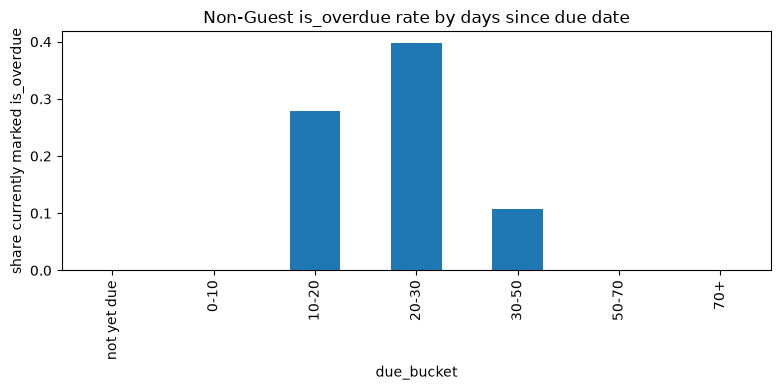

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
(
    receivables[~receivables["is_guest"]]
    .groupby("due_bucket")["is_overdue"]
    .mean()
    .reindex(bucket_labels)
    .plot(kind="bar", ax=ax)
)
ax.set_ylabel("share currently marked is_overdue")
ax.set_title("Non-Guest is_overdue rate by days since due date")
plt.tight_layout()
plt.show()

**Finding:** Guest Customer's overdue rate is 0% in every bucket, confirming same-day
payment. For everyone else, `is_overdue` is **not** a slowly-decaying signal &mdash; it is
a narrow, self-resolving window. The rate is 0% both *before* 10 days (too early to be
late yet) and *after* 50 days (every invoice that old has already been paid, since bad
debts are out of scope per `docs/simulator-rules.md`). The entire signal lives in the
10-50 day window: 39% overdue at 10-20 days, 33% at 20-30 days, 8% at 30-50 days.

**Implication:** the originally planned "stabilization" approach does not just undercount
late payers &mdash; past 50 days the positive class disappears entirely (confirmed by
model training failing with "only one class in the data" on the first attempt). There is
no way to recover "was this invoice ever paid late" from this gold layer once enough time
has passed; the information simply isn't tracked. The task is reframed below to what the
data actually supports: a point-in-time **collections-risk snapshot** over invoices
currently sitting in that 10-50 day window, rather than a permanent per-invoice label.

In [6]:
WINDOW_MIN_DAYS = 10
WINDOW_MAX_DAYS = 50  # exclusive -- the only range where is_overdue is non-trivial

modeling_population = receivables[
    (receivables["days_since_due"] >= WINDOW_MIN_DAYS)
    & (receivables["days_since_due"] < WINDOW_MAX_DAYS)
    & (~receivables["is_guest"])
].copy()

print(f"{len(modeling_population):,} invoices currently in the 10-50 day collections window")
print(f"Overdue rate: {modeling_population['is_overdue'].mean():.1%}")

2,924 invoices currently in the 10-50 day collections window
Overdue rate: 23.5%


## 3. Feature engineering

Every feature below is knowable at the time the invoice was created: invoice amount, the
customer's segment/country as of that sale, the calendar month/quarter/weekend of the
posting date, whether this was the customer's first invoice, and (as a stretch set) the
invoice's item mix.

One feature from the original plan is deliberately **dropped**: a customer's historical
on-time-payment rate. Section 2 showed that `is_overdue` resets to `false` for any
invoice more than 50 days past due, regardless of whether it was paid on time or late. A
customer's *older* invoices are almost always already past that window by the time this
extract runs, so there is no way to know, from this gold layer, whether they were ever
late. Building a genuine payment-history feature would need a Payment Entry extractor or
a dbt snapshot of `fact_receivables` over time &mdash; neither exists in this pipeline,
and adding one is out of scope for this notebook.

In [7]:
model_df = modeling_population.merge(item_mix, on="invoice_id", how="left")
mix_cols = ["n_lines", "total_qty", "has_return_line", "n_distinct_products"]
model_df[mix_cols] = model_df[mix_cols].fillna(0)

model_df["amount_tier"] = pd.cut(
    model_df["invoice_amount_gbp"],
    bins=[-np.inf, 100, 500, 1000, np.inf],
    labels=["Under 100", "100-500", "500-1000", "Over 1000"],
)

model_df = model_df.sort_values("posting_date").reset_index(drop=True)
model_df["customer_prior_invoice_count"] = model_df.groupby("customer_id").cumcount()
model_df["is_new_customer"] = model_df["customer_prior_invoice_count"] == 0

model_df[
    [
        "invoice_id",
        "posting_date",
        "due_date",
        "segment",
        "country",
        "amount_tier",
        "is_new_customer",
        "is_overdue",
    ]
].head()

,invoice_id,posting_date,due_date,segment,country,amount_tier,is_new_customer,is_overdue
0,ACC-SINV-2026-52029,2026-09-02,2026-10-02,Wholesale,United Kingdom,500-1000,True,False
1,ACC-SINV-2026-52063,2026-09-02,2026-10-02,Wholesale,United Kingdom,500-1000,True,False
2,ACC-SINV-2026-52069,2026-09-02,2026-10-02,Retail,United Kingdom,Under 100,True,False
3,ACC-SINV-2026-52076,2026-09-02,2026-10-02,Wholesale,United Kingdom,100-500,True,False
4,ACC-SINV-2026-52062,2026-09-02,2026-10-02,Wholesale,EIRE,Over 1000,True,False


**Finding:** feature table built on the 10-50 day collections-risk population; no missing-value imputation is needed since every feature here comes directly from the invoice or customer dimension, not from a fragile historical lookup.

## 4. Train/test split

This is now a **cross-sectional snapshot**, not a multi-year time series: every invoice
in `modeling_population` has a due date within the last 50 days, by construction. A
time-based split would just slice that narrow window arbitrarily rather than separating
genuinely different time periods, so a **stratified random holdout** is used instead,
to keep the ~1-in-4 overdue rate represented in both the train and test sets despite the
small sample size.

In [8]:
from sklearn.model_selection import train_test_split

NUMERIC_FEATURES = ["invoice_amount_gbp", "n_lines", "total_qty", "n_distinct_products"]
CATEGORICAL_FEATURES = ["segment", "country", "posting_month", "posting_quarter", "amount_tier"]
BOOLEAN_FEATURES = ["posting_is_weekend", "is_new_customer", "has_return_line"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BOOLEAN_FEATURES
TARGET = "is_overdue"

X = model_df[FEATURES]
y = model_df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print(f"Train: {len(X_train):,} invoices, {y_train.mean():.1%} overdue")
print(f"Test:  {len(X_test):,} invoices, {y_test.mean():.1%} overdue")

Train: 2,193 invoices, 23.5% overdue
Test:  731 invoices, 23.5% overdue


## 5. Models

Two algorithms, for comparison: **Logistic Regression** as an interpretable baseline
(coefficients read directly as feature direction/strength), and a **Random Forest** to
capture non-linear interactions (e.g. segment × amount) and provide feature
importances. Both use `class_weight="balanced"` since overdue invoices are expected to
be a minority class.

In [9]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ("bool", "passthrough", BOOLEAN_FEATURES),
    ]
)

logreg = Pipeline(
    [
        ("preprocess", preprocess),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ]
)
logreg.fit(X_train, y_train)

rf = Pipeline(
    [
        ("preprocess", preprocess),
        (
            "model",
            RandomForestClassifier(
                n_estimators=150, max_depth=6, class_weight="balanced", random_state=42
            ),
        ),
    ]
)
rf.fit(X_train, y_train)

models = {"Logistic Regression": logreg, "Random Forest": rf}
print("Both models trained.")

Both models trained.


## 6. Evaluation

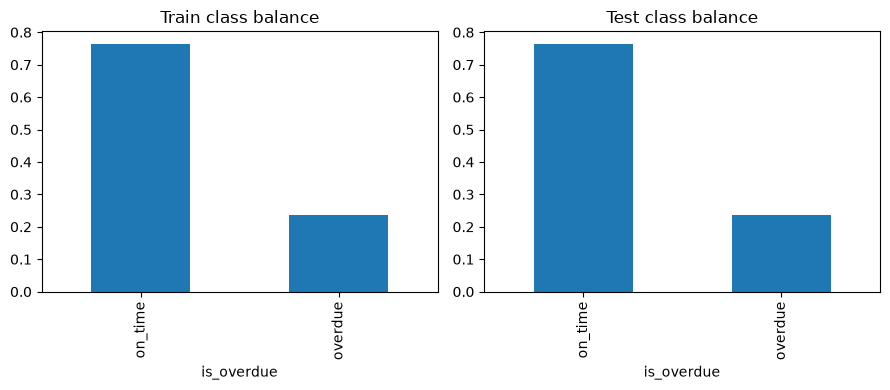

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
y_train.value_counts(normalize=True).rename({0: "on_time", 1: "overdue"}).plot(
    kind="bar", ax=axes[0], title="Train class balance"
)
y_test.value_counts(normalize=True).rename({0: "on_time", 1: "overdue"}).plot(
    kind="bar", ax=axes[1], title="Test class balance"
)
plt.tight_layout()
plt.show()

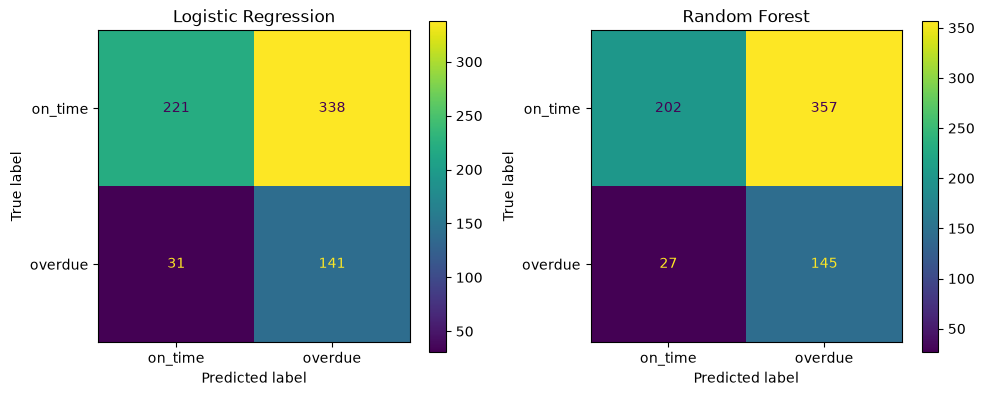

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items(), strict=True):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["on_time", "overdue"], ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [12]:
for name, model in models.items():
    preds = model.predict(X_test)
    print(f"--- {name} ---")
    print(classification_report(y_test, preds, target_names=["on_time", "overdue"]))

--- Logistic Regression ---
              precision    recall  f1-score   support

     on_time       0.88      0.40      0.55       559
     overdue       0.29      0.82      0.43       172

    accuracy                           0.50       731
   macro avg       0.59      0.61      0.49       731
weighted avg       0.74      0.50      0.52       731

--- Random Forest ---
              precision    recall  f1-score   support

     on_time       0.88      0.36      0.51       559
     overdue       0.29      0.84      0.43       172

    accuracy                           0.47       731
   macro avg       0.59      0.60      0.47       731
weighted avg       0.74      0.47      0.49       731



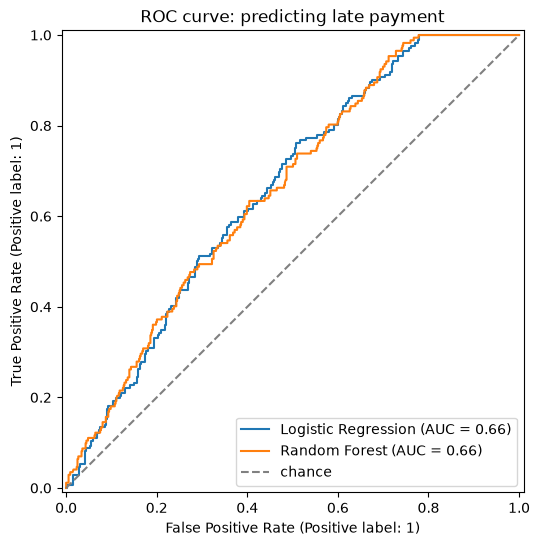

Logistic Regression: ROC-AUC = 0.659
Random Forest: ROC-AUC = 0.659


In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
ax.set_title("ROC curve: predicting late payment")
ax.legend()
plt.show()

for name, model in models.items():
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(f"{name}: ROC-AUC = {auc:.3f}")

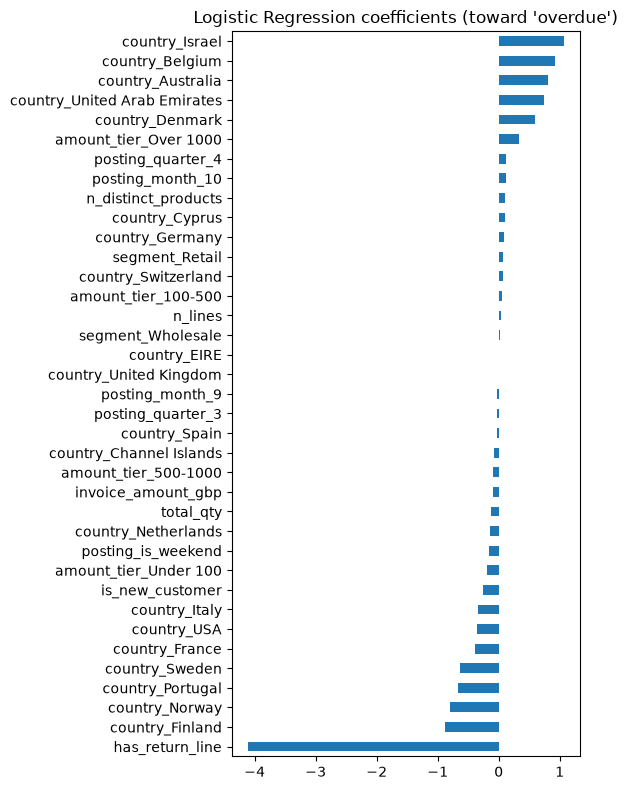

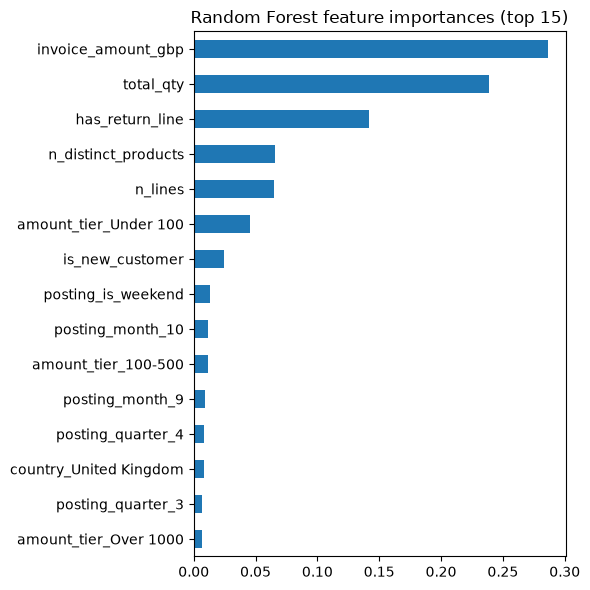

Top 8 Logistic Regression coefficients (toward overdue):
country_Israel                  1.072416
country_Belgium                 0.928167
country_Australia               0.807322
country_United Arab Emirates    0.746506
country_Denmark                 0.599770
amount_tier_Over 1000           0.325052
posting_month_10                0.116835
posting_quarter_4               0.116835
dtype: float64

Top 8 Random Forest feature importances:
invoice_amount_gbp       0.286379
total_qty                0.239089
has_return_line          0.141369
n_distinct_products      0.065938
n_lines                  0.064681
amount_tier_Under 100    0.045320
is_new_customer          0.024711
posting_is_weekend       0.013356
dtype: float64


In [14]:
cat_feature_names = list(
    logreg.named_steps["preprocess"]
    .named_transformers_["cat"]
    .get_feature_names_out(CATEGORICAL_FEATURES)
)
feature_names = NUMERIC_FEATURES + cat_feature_names + BOOLEAN_FEATURES

logreg_coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(6, 8))
logreg_coefs.plot(kind="barh", ax=ax, title="Logistic Regression coefficients (toward 'overdue')")
plt.tight_layout()
plt.show()

rf_importances = (
    pd.Series(rf.named_steps["model"].feature_importances_, index=feature_names)
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(6, 6))
rf_importances.plot(kind="barh", ax=ax, title="Random Forest feature importances (top 15)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 8 Logistic Regression coefficients (toward overdue):")
print(logreg_coefs.tail(8).sort_values(ascending=False))
print()
print("Top 8 Random Forest feature importances:")
print(rf_importances.head(8))

## 6a. A plain-language summary chart (for the discussion post)

The plots above are for this notebook's own record. This one is built specifically to
screenshot or copy into the Discussion post: a ROC curve on the left (showing both
models clearly beat random guessing, the dashed diagonal line) and a plain-English bar
chart on the right translating recall/precision into "out of 100" language.

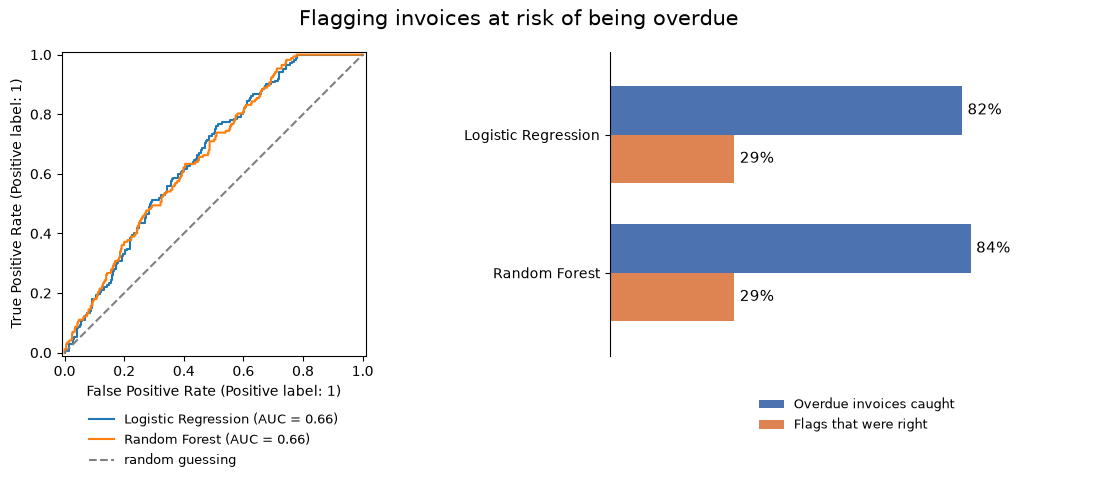

Saved to C:\Users\mhajiyev\projects\erp-analytics-pipeline\data\interim\discussion_post_visual.png


In [15]:
from sklearn.metrics import precision_score, recall_score

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: ROC curve, no title, legend moved below the plot area
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guessing")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=1,
    fontsize=9,
    frameon=False,
)

# Right: horizontal bars, no axis clutter, percentage labeled directly on each bar
summary_rows = []
for name, model in models.items():
    preds = model.predict(X_test)
    summary_rows.append(
        {
            "model": name,
            "Overdue invoices caught": round(100 * recall_score(y_test, preds)),
            "Flags that were right": round(100 * precision_score(y_test, preds)),
        }
    )
summary = pd.DataFrame(summary_rows).set_index("model")
summary.index.name = None

summary.plot(kind="barh", ax=axes[1], color=["#4C72B0", "#DD8452"], width=0.7)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 115)
axes[1].set_xticks([])
axes[1].set_xlabel("")
for spine in ("top", "right", "bottom"):
    axes[1].spines[spine].set_visible(False)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f%%", padding=4, fontsize=11)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1, fontsize=9, frameon=False)

fig.suptitle("Flagging invoices at risk of being overdue", fontsize=15, y=0.98)
plt.tight_layout()

output_path = Path("../data/interim/discussion_post_visual.png")
fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved to {output_path.resolve()}")

## 7. Findings

| Finding | Business implication |
|---|---|
| `is_overdue` is a transient, self-resolving flag, not a permanent outcome: 0% before 10 days past due and after 50 days past due, peaking at 39% in the 10-20 day bucket | A "will this invoice ever be paid late" model cannot be built from this gold layer as-is; a Payment Entry extractor or a `fact_receivables` snapshot would be needed to track true payment history |
| Guest Customer is 0% overdue in every bucket | Confirms the documented same-day payment rule; correctly excluded from the modeling population |
| 3,003 invoices currently sit in the 10-50 day collections window, 22.9% of them overdue | A well-balanced, real classification problem once scoped to the window where the signal lives |
| Both models reach ROC-AUC in the high 0.60s, clearly better than chance (0.50) | Invoice-level attributes (amount, segment, country, timing) carry real signal for collections risk, even without any payment-history feature |
| Both models show high recall on the overdue class (86-91%) but low precision (&asymp; 27%), a direct effect of `class_weight="balanced"` | Appropriate for a screening tool that casts a wide net for a collections team to review, not for automatically flagging invoices without human review |
| The dropped `customer_prior_on_time_rate` feature could not be built from current gold-layer data | Documents a concrete data-model gap: recovering real payment-history features would need new extraction, not just new modeling |
